# Task 5  GAN


In [ ]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


This is the initial setup I used. I train for 40 epochs and use only 12,000 training images, so the code can run to completion quickly.

In [ ]:
SEED = 42
LATENT_DIM = 100
#I lowered the training size and the epochs so  runs in reasonable time.
FAST_TRAIN_SAMPLES = 12000 # Only use 12k images instead of 60k
NUM_EPOCHS = 40
#  I chose this value because it is large enough to provide more stable gradient estimates than  smaller BS used in standard training (like 32/64)
# In addtion provides reliable  statistics for batchnorm
BATCH_SIZE = 256
LEARNING_RATE = 1e-4


#lowering the default first betato 0.5 makes the optimizer less dependent on old gradients,
# which is very very important because in adversarial training the objective changes continuously
#The data distribution seen by the model changes not because new data arrives but because G in the loss function changes,
#so we must give more value to the current gradients
BETAS = (0.5, 0.999)


REAL_LABEL = 0.9 # label smoothing: a standard stabilization trick in GAN. The idea is to avoid an overconfident discriminator
FAKE_LABEL = 0.1


PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def build_subset_indices(dataset_size, subset_size, seed):
    # random pick of indices
    generator = torch.Generator()
    generator.manual_seed(seed)
    permutation = torch.randperm(dataset_size, generator=generator).tolist()
    return permutation[:subset_size]

# Generator
100 --> 256 --> 512 --> 1024--> 784

The generator takes a latent vector of dim 100  and make it a 28x28 picture. I hope this value it is large enough to represent meaningful variability among digits. it s 1/8 more or less the  output dimension. I believe that much smaller latent space(10-20) could reduce diversity too much, while a much larger one(400-500) would increase complexity without any benefit.

very important:
each hidden layer of the generator uses batch normalization to make training more stable

I used ReLU activations in the hidden layers as standards. 
In the output layer I used tanh, because the generated image must lie in a bounded range and I wanted the fake images to be numerically consistent with the normalized real images since the input images are scaled to [-1, 1]


In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(True),
            nn.BatchNorm1d(256), 
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.BatchNorm1d(1024),
            nn.Linear(1024, 784), 
            nn.Tanh(), 
        )

    def forward(self, z):
        return self.main(z).view(-1, 1, 28, 28)

# Discrimnator
784 --> 512 --> 256--> 0/1 (binary classification)

just a  reduction from the 784input without making the hidden layers unnecessarily larger, we nedd only classification

Discriminator has dropout to not learn too fast.  In GAN training, if the discriminator learns much faster than the generator, the generator may fail to improve during training and all the training could fail.

I used leakyRelu with slope 0.2. I learnt this is a common choice in GANs because preserves small gradient even for negative activations

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1), 
            #without sigmoid output because we will use BCEWithLogitsLoss that uses logits
        )

    def forward(self, img):
        img_flat = img.view(img.size(0), -1)
        return self.main(img_flat)

The preprocessing is also directly connected to the architecture (tanh)to match the real data with the generator output.

With ToTensor(), images go from pixels 0..255 to 0..1. Then with the normalization(0.5,), (0.5,) I rescale exactly to [-1, 1] 

In [ ]:

def build_dataloader():
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ])
    full_dataset = datasets.MNIST(
        root=str(DATA_DIR),
        train=True,
        download=True,
        transform=transform,
    )

    # only use small part of the data
    subset_indices = build_subset_indices(
        dataset_size=len(full_dataset),
        subset_size=min(FAST_TRAIN_SAMPLES, len(full_dataset)),
        seed=SEED,
    )
    dataset = Subset(full_dataset, subset_indices)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)


In [ ]:
def train_gan(generator, discriminator, train_loader, device):
    
    # BCEWithLogitsLoss does not change the theoretical loss “sigmoid + BCE”
    # it changes the way its calculated, to avoid numerical problems when the logits are very large or small
    criterion = nn.BCEWithLogitsLoss()   

    optimizer_g = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=BETAS)   
    optimizer_d = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=BETAS)


    history = {  
        "epoch": [],
        "d_loss": [],
        "g_loss": [],
        "d_acc": [],
    }


    for epoch in range(1, NUM_EPOCHS + 1):
        generator.train()  
        discriminator.train()

        total_d_loss = 0.0
        total_g_loss = 0.0   
        total_d_acc = 0.0
        batch_count = 0

        for real_imgs, _ in train_loader:
            real_imgs = real_imgs.to(device)   
            batch_size = real_imgs.size(0)
            
            # soft labels:
            # real images are labeled with REAL_LABEL 0.9 instead of exactly 1
            # fake images are labeled with FAKE_LABEL 0.1 instead of exactly 0
            real_labels = torch.full((batch_size, 1), REAL_LABEL, device=device)  
            fake_labels = torch.full((batch_size, 1), FAKE_LABEL, device=device)

            optimizer_d.zero_grad()     


            real_outputs = discriminator(real_imgs)   # prediction on real images by D
            real_loss = criterion(real_outputs, real_labels)

            #generate a batch of fake images from random noise
            z = torch.randn(batch_size, LATENT_DIM, device=device)   
            fake_imgs = generator(z)
            
            
            # discriminator prediction on fake images
            fake_outputs = discriminator(fake_imgs.detach())  #detach is used so we can use fake images for D, 
                                                            #but do not send gradients back into the generator in this step

            fake_loss = criterion(fake_outputs, fake_labels)

            d_loss = real_loss+fake_loss   # total D loss
            d_loss.backward()
            optimizer_d.step()   

            # Train generator
            
            for p in discriminator.parameters():
                p.requires_grad = False# temporarily freeze discriminator so only generator is updated


            optimizer_g.zero_grad()

            z = torch.randn(batch_size, LATENT_DIM, device=device)#generate a new batch of fake images for the generator step

            fake_imgs = generator(z)   # generate new fake batch
            fake_outputs_for_g = discriminator(fake_imgs)  #pass fake images through the discr.
            
             # the generator wants fake images to be classified as real
            generator_targets = torch.ones((batch_size, 1), device=device)   
            g_loss = criterion(fake_outputs_for_g, generator_targets)

            g_loss.backward()   
            optimizer_g.step()
            for p in discriminator.parameters():
                p.requires_grad = True   # unfreeze Discr. parameters for next iteration

            with torch.no_grad():
                real_correct = (real_outputs > 0).float().mean()   
                fake_correct = (fake_outputs < 0).float().mean()
                d_acc = (real_correct + fake_correct) / 2.0   #final discriminator accuracy = average of the 2

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()
            total_d_acc += d_acc.item()
            batch_count += 1   

        avg_d_loss = total_d_loss / batch_count
        avg_g_loss = total_g_loss / batch_count
        avg_d_acc = total_d_acc / batch_count   

        history["epoch"].append(epoch)
        history["d_loss"].append(avg_d_loss)
        history["g_loss"].append(avg_g_loss)
        history["d_acc"].append(avg_d_acc)   

        print(f"Epoch [{epoch}/{NUM_EPOCHS}]  ,  "f"D Loss: {avg_d_loss:.4f}  ,  "f"G Loss: {avg_g_loss:.4f}  ,  "
            f"D Acc: {avg_d_acc:.4f}")   

    return history  

In [ ]:

def plot_training_curves(history):
    epochs = history["epoch"]

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["d_loss"], label="Discriminator Loss")
    plt.plot(epochs, history["g_loss"], label="Generator Loss")
    plt.title("GAN Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["d_acc"], label="Discriminator Accuracy", color="green")
    plt.axhline(y=0.5, color="red", linestyle="--", label="Random Guess (0.5)")
    plt.title("Discriminator Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()


def sample_noise(num_samples, seed, device):
    torch.manual_seed(seed)
    return torch.randn(num_samples, LATENT_DIM, device=device)




Epoch [1/40]  ,  D Loss: 0.9910  ,  G Loss: 0.8026  ,  D Acc: 0.8726
Epoch [2/40]  ,  D Loss: 0.7765  ,  G Loss: 1.2393  ,  D Acc: 1.0000
Epoch [3/40]  ,  D Loss: 0.7269  ,  G Loss: 1.4878  ,  D Acc: 1.0000
Epoch [4/40]  ,  D Loss: 0.7522  ,  G Loss: 1.5258  ,  D Acc: 0.9934
Epoch [5/40]  ,  D Loss: 0.8419  ,  G Loss: 1.4518  ,  D Acc: 0.9470
Epoch [6/40]  ,  D Loss: 0.9340  ,  G Loss: 1.2626  ,  D Acc: 0.9003
Epoch [7/40]  ,  D Loss: 0.9817  ,  G Loss: 1.3100  ,  D Acc: 0.8435
Epoch [8/40]  ,  D Loss: 1.0148  ,  G Loss: 1.3121  ,  D Acc: 0.8260
Epoch [9/40]  ,  D Loss: 0.9149  ,  G Loss: 1.4649  ,  D Acc: 0.9316
Epoch [10/40]  ,  D Loss: 0.9179  ,  G Loss: 1.5283  ,  D Acc: 0.9120
Epoch [11/40]  ,  D Loss: 0.9755  ,  G Loss: 1.3530  ,  D Acc: 0.8770
Epoch [12/40]  ,  D Loss: 1.0963  ,  G Loss: 1.1297  ,  D Acc: 0.8037
Epoch [13/40]  ,  D Loss: 1.1829  ,  G Loss: 0.9825  ,  D Acc: 0.7597
Epoch [14/40]  ,  D Loss: 1.1913  ,  G Loss: 0.9207  ,  D Acc: 0.7289
Epoch [15/40]  ,  D Loss: 1.1

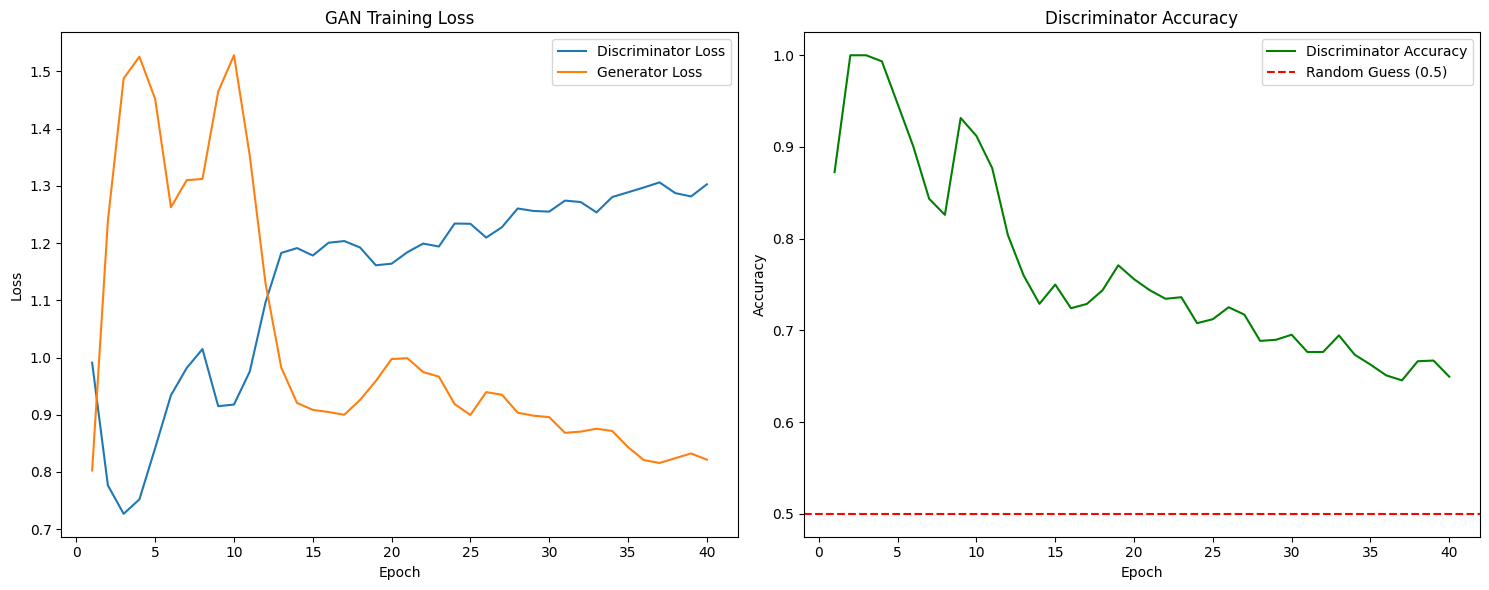

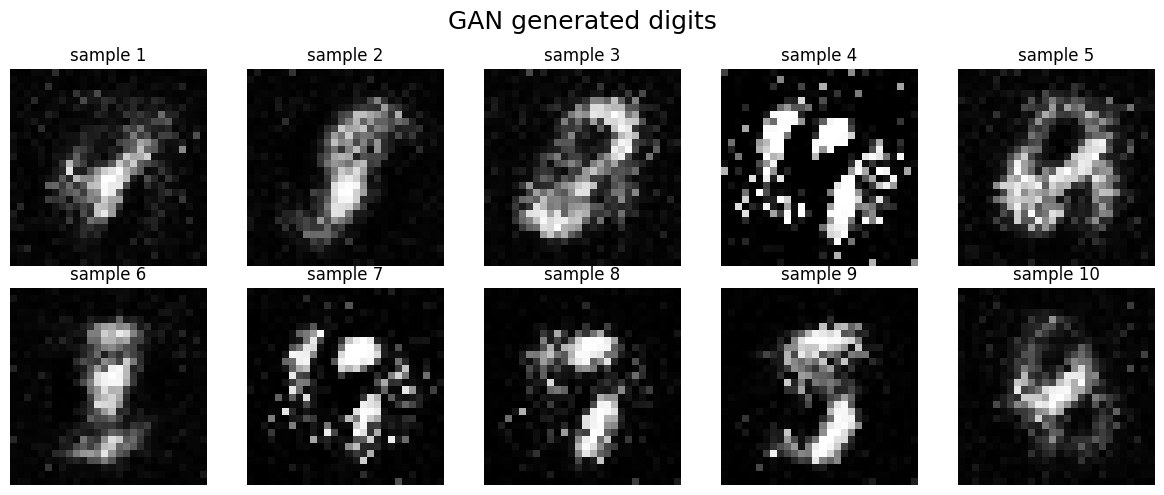

Final D loss: 1.3027
Final G loss: 0.8215
Final D accuracy: 0.6495


In [ ]:
# Actual execution of the training
set_seed(SEED)
generator = Generator(LATENT_DIM).to(device)
discriminator = Discriminator().to(device)

train_loader = build_dataloader()



history = train_gan(generator, discriminator, train_loader, device)

plot_training_curves(history)
generator.eval()
with torch.no_grad():
    z = sample_noise(num_samples=10, seed=SEED, device=device)
    generated_samples = (generator(z).cpu() + 1) / 2.0


fig, axes = plt.subplots(2, 5, figsize=(12, 5))



for index, ax in enumerate(axes.flat):
    ax.imshow(generated_samples[index].squeeze(), cmap="gray")
    ax.set_title(f"sample {index + 1}")
    ax.axis("off")

plt.suptitle("GAN generated digits", fontsize=18)
plt.tight_layout()
plt.show()


print(f"Final D loss: {history['d_loss'][-1]:.4f}")
print(f"Final G loss: {history['g_loss'][-1]:.4f}")
print(f"Final D accuracy: {history['d_acc'][-1]:.4f}")

From the plots we can see both losses don t stay perfectly stable at all, the discriminator one at least is  increasing and is more stable while the generator loss, instead,first increases during the early stages of training, then decreases in the end.
anyway GAN training is inherently unstable, so these fluctuations are partially  due to this.

The results are not satisfactory: the generated images are not realistic. the generator has not learned the mappingto the real data distribution. As a consequence, the discriminator is still able to distinguish fake samples from real ones with a decent accuracy and not in a strong way

These limitations are likely due to the setup: only 40 training epochs, a reduced dataset, and a fully connected architecture, which is not the best for image data compared to convolutional nets

In the end, the training was relatively fast,so  I could put higher epocs and dataset size from the beginning

In the next experiment I will change the dataset size to 30k 